In [16]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

from scipy.stats import norm
from statsmodels.graphics.gofplots import qqplot
from statsmodels.graphics.tsaplots import plot_acf

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller
from itertools import product

import random

from pathlib import Path
import sys
# Agregar el path del directorio "code"
code_path = Path("../code").resolve()
if str(code_path) not in sys.path:
    sys.path.insert(0, str(code_path))


import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from TimeSeriesLib import MeanRollingForecast, LastRollingForecast, SarimaxRollingForecast

import warnings
from statsmodels.tools.sm_exceptions import EstimationWarning

warnings.simplefilter('ignore', EstimationWarning)
warnings.simplefilter('ignore', UserWarning) # A veces statsmodels lanza warnings por convergencia

In [17]:
#TODO Pipeline que procese todo cammesa_data_x
df_a = pd.read_csv("../datasets/cammesa_data_A.csv",parse_dates=["fecha"])
df_b = pd.read_csv("../datasets/cammesa_data_B.csv",parse_dates=["fecha"])

df_combinado = pd.concat([df_a, df_b], ignore_index=True)

# 4. Eliminar duplicados basados ÚNICAMENTE en el campo 'fecha'
# 'keep="first"' conserva el primer registro encontrado (puedes usar 'keep="last"' si prefieres el de B)
df = df_combinado.drop_duplicates(subset=["fecha"], keep="first")

# 5. Ordenar por fecha para mantener la coherencia temporal
df = df.sort_values(by="fecha").reset_index(drop=True)

print(f"Filas originales A: {len(df_a)}, B: {len(df_b)}")
print(f"Filas combinadas sin duplicados: {len(df)}")



Filas originales A: 64159, B: 74293
Filas combinadas sin duplicados: 82967


Agrupamos diariamente

In [18]:
df = df.iloc[:-1] #quito el dia ultimo por no tener datos

In [19]:
df = df[["fecha", "demanda", "temp", "esDiaHabil"]]
df['fecha'] = pd.to_datetime(df['fecha']).dt.tz_localize(None)
#agrupemos
df = (
    df.groupby(df['fecha'].dt.to_period('D'))
    .agg({
        'demanda': 'mean',
        'temp': 'mean',
        'esDiaHabil': 'mean'  # En pandas, la media de un booleano calcula la proporción
    })
    .reset_index()
)

df['esDiaHabil'] = df['esDiaHabil'].astype(int)

In [ ]:
df["demanda"] = df["demanda"]/1000
df["cuad_temp"] = (df["temp"]-20)**2

No hay nulos. ¿Hay faltantes?

In [23]:
lrange = pd.period_range(start=df['fecha'].min(), end=df['fecha'].max(), freq='D')
dtdiff = lrange.difference(df['fecha'])

# 3. Mostrar el resultado
if len(dtdiff) == 0:
    print("Ok fechas")
else:
    print("Hay faltantes")
    print(dtdiff)

Ok fechas


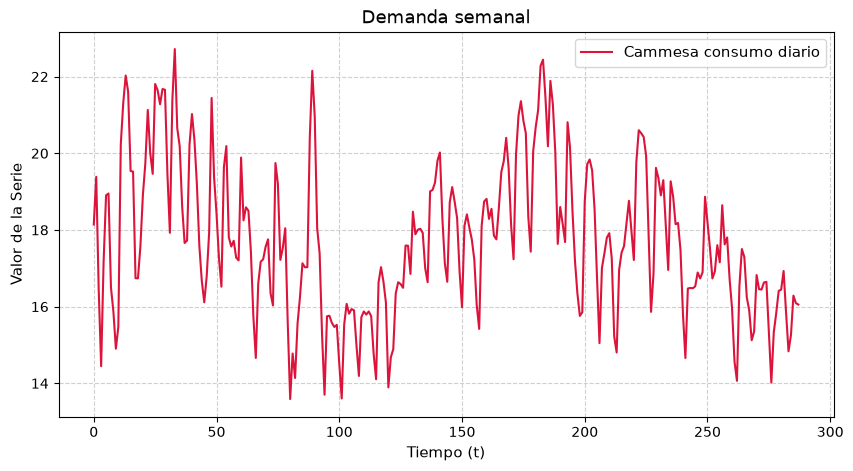

In [24]:
plt.figure(figsize=(10, 5))
plt.plot(df["demanda"], label=f'Cammesa consumo diario', color='crimson', linewidth=1.5)
plt.title('Demanda semanal', fontsize=13)
plt.xlabel('Tiempo (t)', fontsize=11)
plt.ylabel('Valor de la Serie', fontsize=11)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

¿Es estacionaria?

In [25]:
ADF_result = adfuller(df["demanda"], result_object=False) #result_object=False para silenciar warning de deprecado 2027
#print(f'ADF Statistic: {ADF_result[0]}')
print(f'p-value: {ADF_result[1]}')

p-value: 0.1780913440115779


p-value>0.05, diferenciemos.

In [26]:
df_diff = df.copy()
df_diff["diff"] = df['demanda'].diff()
df_diff = df_diff.dropna(subset=["diff"]).reset_index(drop=True)

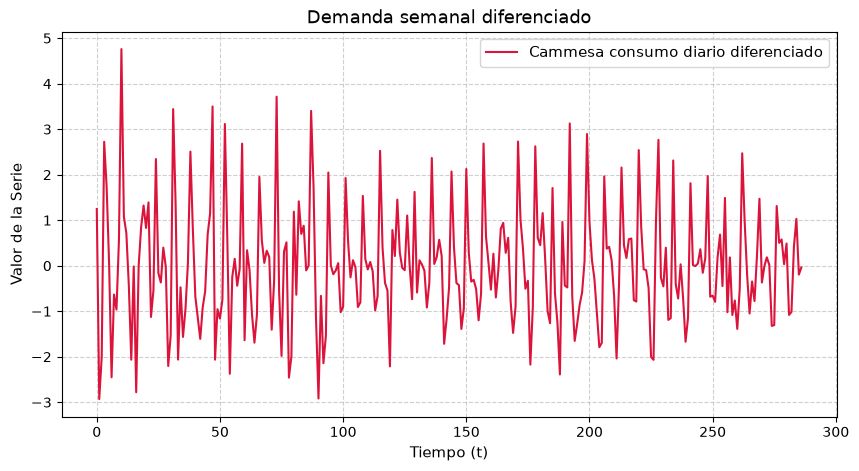

In [27]:
plt.figure(figsize=(10, 5))
plt.plot(df_diff["diff"], label=f'Cammesa consumo diario diferenciado', color='crimson', linewidth=1.5)
plt.title('Demanda semanal diferenciado', fontsize=13)
plt.xlabel('Tiempo (t)', fontsize=11)
plt.ylabel('Valor de la Serie', fontsize=11)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


In [28]:
ADF_result = adfuller(df_diff["diff"], result_object=False) #result_object=False para silenciar warning de deprecado 2027
#print(f'ADF Statistic: {ADF_result[0]}')
print(f'p-value: {ADF_result[1]}')

p-value: 9.60745677345531e-07


Es estacionaria

¿Hay autocorrelacion, hay autocorrelacion parcial?

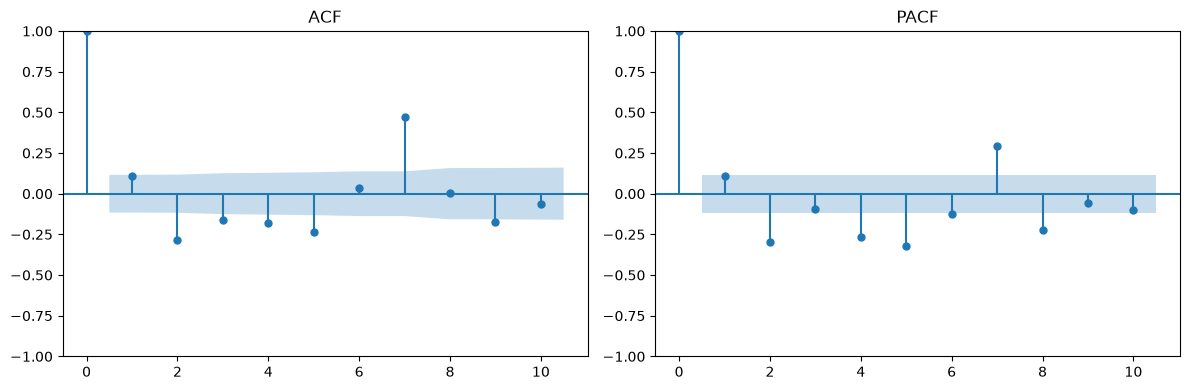

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# ACF
plot_acf(df_diff["diff"], ax=axes[0], lags=10, alpha=0.05)
axes[0].set_title("ACF")

# PACF
plot_pacf(df_diff["diff"], ax=axes[1], lags=10, alpha=0.05, method="ywm")
axes[1].set_title("PACF")

plt.tight_layout()
plt.show()

Nada claro...

¿Hay estacionalidad? (Serie original). Se que es de "7 dias", por ahora ignoro.

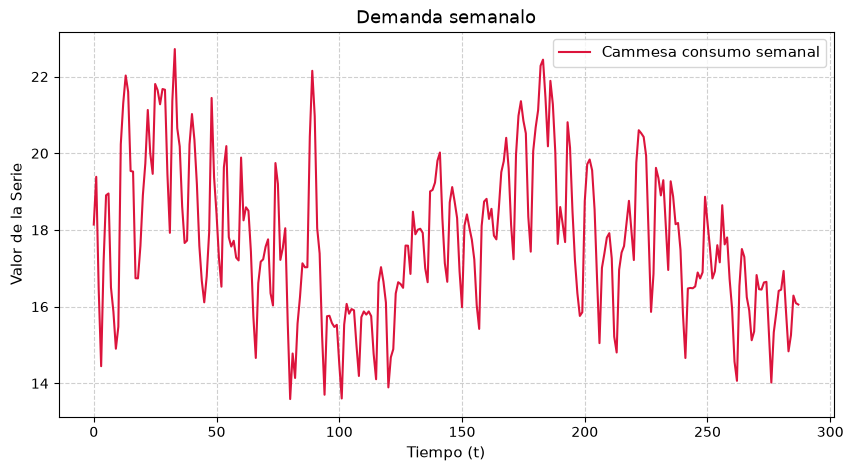

In [30]:
plt.figure(figsize=(10, 5))
plt.plot(df["demanda"], label=f'Cammesa consumo semanal', color='crimson', linewidth=1.5)
plt.title('Demanda semanalo', fontsize=13)
plt.xlabel('Tiempo (t)', fontsize=11)
plt.ylabel('Valor de la Serie', fontsize=11)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Entonces no parece AR puro ni MA puro. Probemos alternativas

In [31]:
window  = 1 # Solo un paso adelante.
train_percent = 0.8
target_col = "demanda"
#exo_fields = ["temp", "esDiaHabil"]
exo_fields = ["esDiaHabil", "cuad_temp"]
df = df[exo_fields+[target_col]] 

In [32]:
#Demora algunos minutos...
ps      = range(0, 2, 1)    
d       = 1 #Esto ya se que es uno
qs      = range(0, 2, 1)


PS      = range(0, 2, 1)    
D       = 0 #Me la juego que es 0
QS      = range(0, 2, 1)
S       = 7 #Semana



order_list = list(product(ps, qs, PS, QS))

results = []
for p, q, P, Q in order_list:
    try:
        model = SarimaxRollingForecast(window=window, train_percent=0.8, target_col=target_col, order=(p, d, q), seasonal_order=(P,D,Q,S))
        model.backtest(df)
        
        score = model.score()
        results.append([(p, q, P, Q), score])
        
    except Exception as e:
        print(f"Error con la orden ({p}, {q}), omitiendo... {e}")
        continue

Verifiquemos ganador

In [33]:
result_df = pd.DataFrame(results)
result_df.columns = ['(p,q,P,Q)', 'MSE']
#Sort in ascending order, lower MSE is better
result_df = result_df.sort_values(by='MSE', ascending=True).reset_index(drop=True)
result_df.loc[:5,:]

,"(p,q,P,Q)",MSE
0,"(0, 1, 1, 1)",0.190948
1,"(1, 0, 1, 1)",0.193529
2,"(1, 1, 1, 1)",0.194950
3,"(0, 0, 1, 1)",0.196877
4,"(1, 1, 1, 0)",0.258380
5,"(1, 0, 1, 0)",0.268680


Ahora los modelos ¿Puedo ganar?

In [34]:
df_backtest = df[exo_fields + [target_col]].copy()
best_p, best_q, best_P, best_Q = result_df.loc[0, "(p,q,P,Q)"]


estMean      = MeanRollingForecast(window=window, train_percent=train_percent, mean_steps=5)
df["mean"] = estMean.backtest(df[target_col])

estLast      = LastRollingForecast(window=window, train_percent=train_percent)
df["last"] =estLast.backtest(df[target_col])

estSarima   = SarimaxRollingForecast(
    window=window,
    train_percent=train_percent,
    order=(int(best_p), d, int(best_q)),
    seasonal_order=(int(best_P), D, int(best_Q), S),
    target_col=target_col,
)
df["sarima"] = estSarima.backtest(df[target_col])
 


In [35]:

estSarimaX   = SarimaxRollingForecast(
    window=window,
    train_percent=train_percent,
    order=(int(best_p), d, int(best_q)),
    seasonal_order=(int(best_P), D, int(best_Q), S),
    target_col=target_col,
)
df["sarimaX"] = estSarimaX.backtest(df_backtest)



Determinamos window = 1

Revisar variables exogenas y porque no mejora. Es dia habil deberia ayudar a un mejor pronostico

Mean: 1.40, Last: 0.89, sarima: 0.38, sarimaX: 0.19


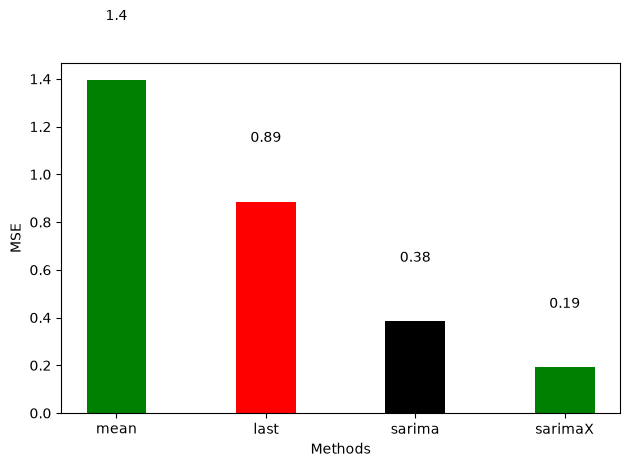

In [36]:
print("Mean: {:.2f}, Last: {:.2f}, sarima: {:.2f}, sarimaX: {:.2f}".format(estMean.score(), 
                                                                        estLast.score(), estSarima.score(),
                                                                        estSarimaX.score()))
fig, ax = plt.subplots()
x = ['mean', 'last', 'sarima', 'sarimaX']
y = [estMean.score(), estLast.score(), estSarima.score(), estSarimaX.score()]
ax.bar(x, y, width=0.4, color=['g', 'r', 'k'])
ax.set_xlabel('Methods')
ax.set_ylabel('MSE')
#ax.set_ylim(0, 5)
for index, value in enumerate(y):
    plt.text(x=index, y=value+0.25, s=str(round(value, 2)), ha='center')
plt.tight_layout()
plt.show()

¿Las variables no han aportado?

In [34]:
df

,temp,esDiaHabil,demanda,mean,last,sarima,sarimaX
0,26.758947,0,18.140847,NaN,NaN,NaN,NaN
1,24.533333,1,19.386094,NaN,NaN,NaN,NaN
2,19.660417,0,16.456097,NaN,NaN,NaN,NaN
3,19.698958,0,14.446816,NaN,NaN,NaN,NaN
4,23.171875,1,17.170167,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...
283,13.165625,0,14.834681,16.293463,15.849878,14.999528,15.007313
284,13.827083,0,15.257764,16.093883,14.834681,16.898682,15.468570
285,15.579167,1,16.288219,15.863411,15.257764,15.274144,17.118229
286,16.080208,1,16.092285,15.832291,16.288219,16.545480,15.861524


¿Y ahora que paso? ;)

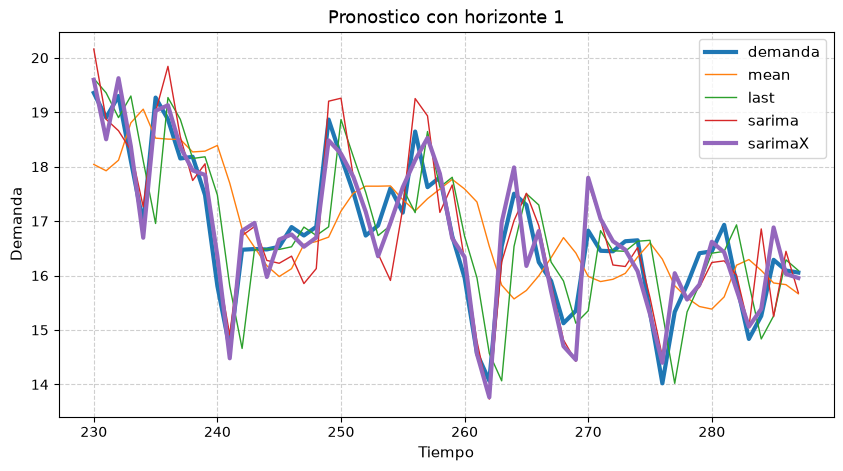

In [37]:
df_plot = df[["demanda", "mean", "last", "sarima", "sarimaX"]]

styles = {"demanda": {"linewidth":3}, 
          "mean": {"linewidth":1}, 
          "last": {"linewidth":1}, 
          "sarima":{"linewidth":1},
          "sarimaX":{"linewidth":3}}

plt.figure(figsize=(10, 5))
for col in df_plot.columns:
    plt.plot(df_plot.index[estSarima.train_len_:], df_plot.loc[df_plot.index[estSarima.train_len_:], col], label=f'{col}', linewidth=styles[col]["linewidth"])

plt.title(f'Pronostico con horizonte {window}', fontsize=13)
plt.xlabel('Tiempo', fontsize=11)
plt.ylabel('Demanda', fontsize=11)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

¿Y los residuos? Falto algo mas de información pero no hay correlación obvia.

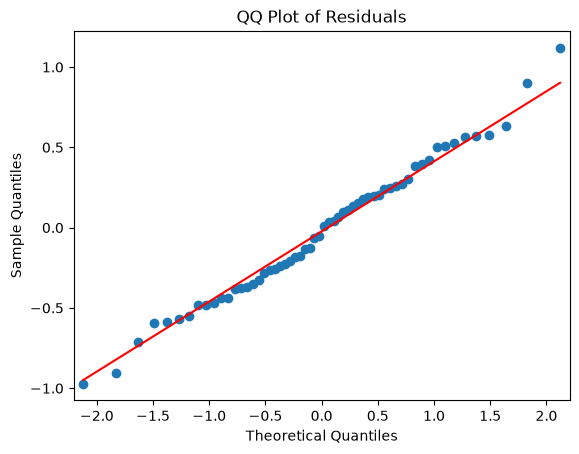

In [38]:
residuals = estSarimaX.resid_
qqplot(residuals, line='s');
plt.title('QQ Plot of Residuals')
plt.show()


Los residuos parecen tener una distribucion normal, podriamos considerar una pronostico válido.

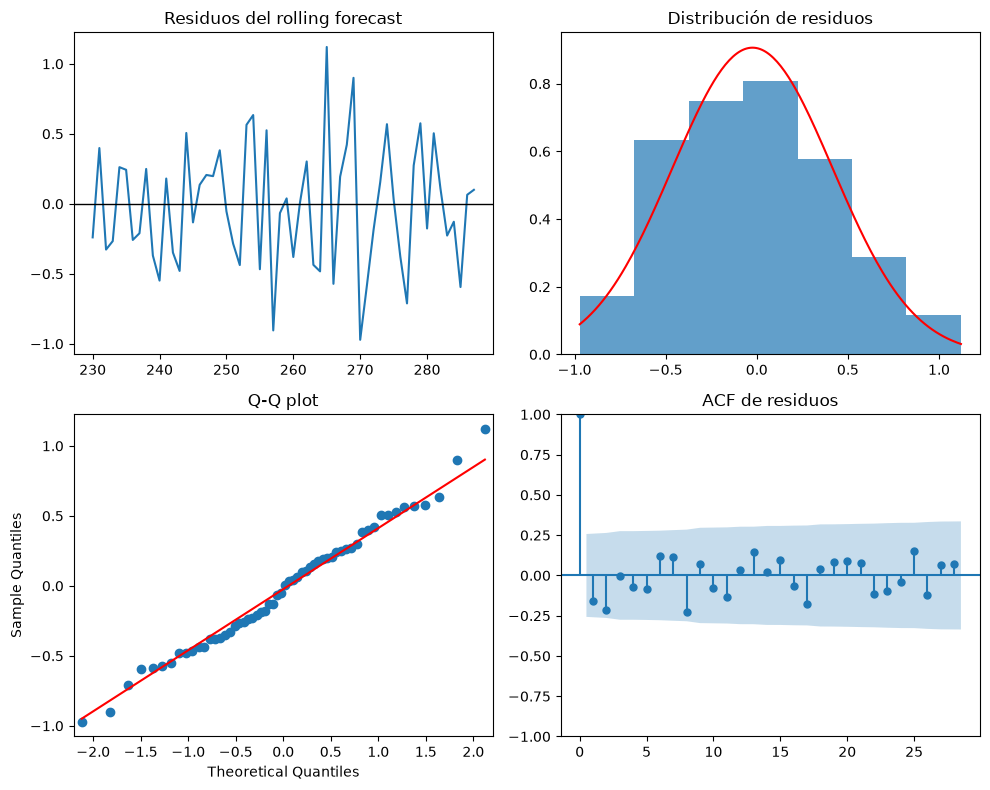

In [39]:
residuals = estSarimaX.resid_.dropna()
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

# Residuos a lo largo del tiempo
axes[0, 0].plot(residuals.index, residuals)
axes[0, 0].axhline(0, color="black", linewidth=1)
axes[0, 0].set_title("Residuos del rolling forecast")

# Distribución de los residuos comparada con una normal
axes[0, 1].hist(residuals, bins="auto", density=True, alpha=0.7)
x = np.linspace(residuals.min(), residuals.max(), 200)
axes[0, 1].plot(x, norm.pdf(x, residuals.mean(), residuals.std()), color="red")
axes[0, 1].set_title("Distribución de residuos")

# Gráfico Q-Q
qqplot(residuals, line="s", ax=axes[1, 0])
axes[1, 0].set_title("Q-Q plot")

# Autocorrelación de los residuos
lags = min(40, len(residuals) // 2 - 1)
plot_acf(residuals, lags=lags, ax=axes[1, 1])
axes[1, 1].set_title("ACF de residuos")

plt.tight_layout()
plt.show()